In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/license.txt
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/image-labels.csv
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings/barretts/6548c39a-3f73-491e-99b9-4c364adf23ff.jpg
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings/barretts/fee3b50b-abad-4bc5-a909-cf1b291f7ef7.jpg
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings/barretts/1aab090c-fd5d-45ae-b7a5-32c5eca64840.jpg
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings/barretts/b470a84e-6560-4d7c-bb4e-2dbcbd96d17d.jpg
/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings/barretts/1778d904-b13e-4461-9cd4-6a5bf1d3b37c.jpg
/kaggle/input/datasets/kelkalot/the-hyper-kvasi

In [3]:
import os
from pathlib import Path
import kagglehub
from sklearn.model_selection import train_test_split

# 1. Download/locate dataset path
try:
    DATASET_PATH = kagglehub.dataset_download('kelkalot/the-hyper-kvasir-dataset')
except Exception as e:
    DATASET_PATH = "/kaggle/input/the-hyper-kvasir-dataset"

print(f"Dataset root path: {DATASET_PATH}")

# 2. Dynamic directory resolver that searches for directories with image files
def find_dataset_base_dir(root_path):
    # Walk through directory tree to find subfolders containing image files
    for path, dirs, files in os.walk(root_path):
        # Ignore hidden folders
        if any(part.startswith('.') for part in Path(path).parts):
            continue
        # Check if current directory contains image files
        image_files = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if len(image_files) > 0:
            # The parent of this folder is the dataset base containing class subfolders
            return os.path.dirname(path)
    return root_path

TARGET_DIR = find_dataset_base_dir(DATASET_PATH)
print(f"Resolved Class Base Directory: {TARGET_DIR}")

# 3. Load image filepaths and numerical labels
def load_filepaths_and_labels(data_dir):
    filepaths = []
    labels = []
    
    classes = sorted([
        d for d in os.listdir(data_dir) 
        if os.path.isdir(os.path.join(data_dir, d)) and not d.startswith('.')
    ])
    
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    
    for cls_name in classes:
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                filepaths.append(os.path.join(cls_dir, fname))
                labels.append(class_to_idx[cls_name])
                
    return filepaths, labels, classes, class_to_idx

filepaths, labels, class_names, class_to_idx = load_filepaths_and_labels(TARGET_DIR)
num_classes = len(class_names)

print(f"\n✅ Total images loaded: {len(filepaths)}")
print(f"✅ Total classes ({num_classes}): {class_names}")

# 4. Stratified Train / Val / Test Split
train_paths, test_paths, train_labels, test_labels = train_test_split(
    filepaths, labels, test_size=0.30, stratify=labels, random_state=42
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    test_paths, test_labels, test_size=0.50, stratify=test_labels, random_state=42
)

print(f"\nTrain: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")

Dataset root path: /kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset
Resolved Class Base Directory: /kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings

✅ Total images loaded: 757
✅ Total classes (4): ['barretts', 'barretts-short-segment', 'esophagitis-a', 'esophagitis-b-d']

Train: 529 | Val: 114 | Test: 114


Using device: cuda
Dataset root path: /kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset
Resolved Class Base Directory: /kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images/upper-gi-tract/pathological-findings
Loaded 757 images across 4 classes.
Train samples: 529 | Val samples: 114 | Test samples: 114

       Training Architecture: ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 212MB/s]


Epoch [01/10] | Train Loss: 1.1992 Acc: 51.80% | Val Loss: 1.0086 Acc: 57.02%
Epoch [02/10] | Train Loss: 0.9247 Acc: 66.16% | Val Loss: 0.9228 Acc: 70.18%
Epoch [03/10] | Train Loss: 0.8037 Acc: 68.43% | Val Loss: 0.8749 Acc: 72.81%
Epoch [04/10] | Train Loss: 0.6831 Acc: 72.21% | Val Loss: 0.8691 Acc: 70.18%
Epoch [05/10] | Train Loss: 0.5818 Acc: 75.61% | Val Loss: 0.8836 Acc: 73.68%
Epoch [06/10] | Train Loss: 0.5410 Acc: 78.07% | Val Loss: 0.8906 Acc: 74.56%
Epoch [07/10] | Train Loss: 0.4893 Acc: 78.83% | Val Loss: 0.8731 Acc: 71.93%
Epoch [08/10] | Train Loss: 0.4415 Acc: 79.58% | Val Loss: 0.8900 Acc: 73.68%
Epoch [09/10] | Train Loss: 0.4221 Acc: 81.85% | Val Loss: 0.8683 Acc: 72.81%
Epoch [10/10] | Train Loss: 0.4289 Acc: 81.85% | Val Loss: 0.8791 Acc: 72.81%

[ResNet50] Test Acc: 73.68% | Precision: 0.6470 | Recall: 0.7368 | F1: 0.6879

       Training Architecture: ResNet50 + CBAM
Epoch [01/10] | Train Loss: 1.3134 Acc: 48.96% | Val Loss: 1.2412 Acc: 54.39%
Epoch [02/10] | 

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Epoch [01/10] | Train Loss: 1.3323 Acc: 39.89% | Val Loss: 1.2630 Acc: 62.28%
Epoch [02/10] | Train Loss: 1.1097 Acc: 63.89% | Val Loss: 1.0725 Acc: 66.67%
Epoch [03/10] | Train Loss: 0.9700 Acc: 68.62% | Val Loss: 0.9548 Acc: 67.54%
Epoch [04/10] | Train Loss: 0.8814 Acc: 69.00% | Val Loss: 0.8928 Acc: 67.54%
Epoch [05/10] | Train Loss: 0.8241 Acc: 71.08% | Val Loss: 0.8612 Acc: 68.42%
Epoch [06/10] | Train Loss: 0.7757 Acc: 70.32% | Val Loss: 0.8358 Acc: 68.42%
Epoch [07/10] | Train Loss: 0.7725 Acc: 71.46% | Val Loss: 0.8168 Acc: 70.18%
Epoch [08/10] | Train Loss: 0.7316 Acc: 74.67% | Val Loss: 0.8156 Acc: 71.05%
Epoch [09/10] | Train Loss: 0.7269 Acc: 73.72% | Val Loss: 0.8125 Acc: 71.05%
Epoch [10/10] | Train Loss: 0.7277 Acc: 75.05% | Val Loss: 0.8114 Acc: 71.05%

[MobileNetV2] Test Acc: 72.81% | Precision: 0.6498 | Recall: 0.7281 | F1: 0.6786

       Training Architecture: Xception


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Epoch [01/10] | Train Loss: 1.2005 Acc: 52.55% | Val Loss: 0.9451 Acc: 67.54%
Epoch [02/10] | Train Loss: 0.8925 Acc: 67.86% | Val Loss: 0.8364 Acc: 68.42%
Epoch [03/10] | Train Loss: 0.7194 Acc: 72.21% | Val Loss: 0.8105 Acc: 70.18%
Epoch [04/10] | Train Loss: 0.6269 Acc: 75.61% | Val Loss: 0.7909 Acc: 71.05%
Epoch [05/10] | Train Loss: 0.5257 Acc: 78.45% | Val Loss: 0.7837 Acc: 72.81%
Epoch [06/10] | Train Loss: 0.4665 Acc: 81.10% | Val Loss: 0.8085 Acc: 71.05%
Epoch [07/10] | Train Loss: 0.4348 Acc: 82.61% | Val Loss: 0.8031 Acc: 71.93%
Epoch [08/10] | Train Loss: 0.4266 Acc: 82.80% | Val Loss: 0.7976 Acc: 71.93%
Epoch [09/10] | Train Loss: 0.3845 Acc: 84.88% | Val Loss: 0.8085 Acc: 71.93%
Epoch [10/10] | Train Loss: 0.3811 Acc: 84.88% | Val Loss: 0.8088 Acc: 71.93%

[Xception] Test Acc: 71.93% | Precision:

100%|██████████| 30.8M/30.8M [00:00<00:00, 204MB/s]


Epoch [01/10] | Train Loss: 1.0252 Acc: 60.11% | Val Loss: 0.8779 Acc: 68.42%
Epoch [02/10] | Train Loss: 0.7808 Acc: 70.70% | Val Loss: 0.8326 Acc: 70.18%
Epoch [03/10] | Train Loss: 0.6648 Acc: 75.24% | Val Loss: 0.8336 Acc: 71.05%
Epoch [04/10] | Train Loss: 0.5964 Acc: 77.88% | Val Loss: 0.8303 Acc: 71.93%
Epoch [05/10] | Train Loss: 0.5025 Acc: 81.10% | Val Loss: 0.8191 Acc: 72.81%
Epoch [06/10] | Train Loss: 0.4539 Acc: 83.93% | Val Loss: 0.8187 Acc: 72.81%
Epoch [07/10] | Train Loss: 0.3994 Acc: 86.20% | Val Loss: 0.8067 Acc: 73.68%
Epoch [08/10] | Train Loss: 0.3696 Acc: 87.33% | Val Loss: 0.8126 Acc: 71.93%
Epoch [09/10] | Train Loss: 0.3494 Acc: 88.66% | Val Loss: 0.8161 Acc: 71.05%
Epoch [10/10] | Train Loss: 0.3596 Acc: 88.28% | Val Loss: 0.8173 Acc: 70.18%

[DenseNet121] Test Acc: 72.81% | Precision: 0.7007 | Recall: 0.7281 | F1: 0.6968

================ FINAL COMPARISON MATRIX ================
          Model  Accuracy (%)  Precision  Recall  F1-Score
       ResNet50     

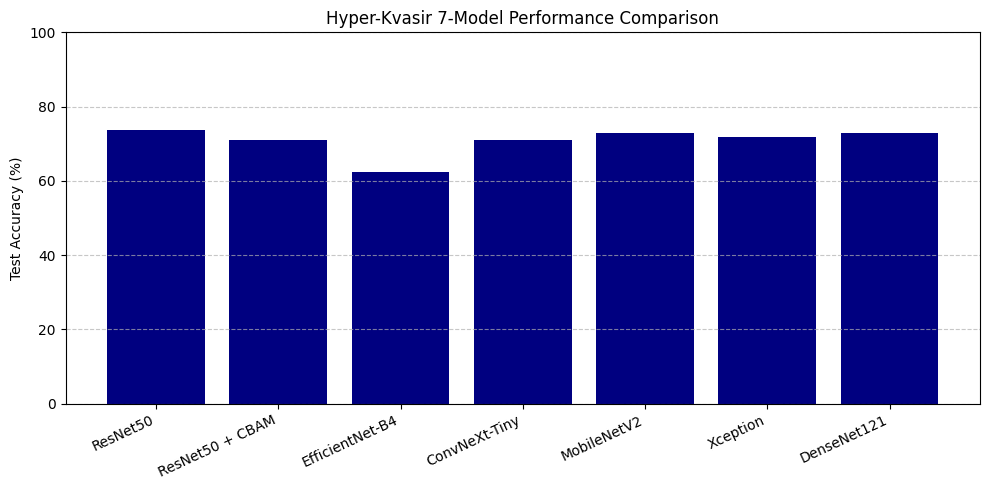

In [1]:
# ==========================================
# Step 1: Install Dependencies & Imports
# ==========================================
!pip install timm torchmetrics -q

import os
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import timm
import kagglehub

# Fix random seed for reproducibility
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# ==========================================
# Step 2: Auto-Detect Path & Load Data Splits
# ==========================================
try:
    DATASET_PATH = kagglehub.dataset_download('kelkalot/the-hyper-kvasir-dataset')
except Exception as e:
    DATASET_PATH = "/kaggle/input/the-hyper-kvasir-dataset"

print(f"Dataset root path: {DATASET_PATH}")

def find_dataset_base_dir(root_path):
    for path, dirs, files in os.walk(root_path):
        if any(part.startswith('.') for part in Path(path).parts):
            continue
        image_files = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if len(image_files) > 0:
            return os.path.dirname(path)
    return root_path

TARGET_DIR = find_dataset_base_dir(DATASET_PATH)
print(f"Resolved Class Base Directory: {TARGET_DIR}")

def load_filepaths_and_labels(data_dir):
    filepaths = []
    labels = []
    
    classes = sorted([
        d for d in os.listdir(data_dir) 
        if os.path.isdir(os.path.join(data_dir, d)) and not d.startswith('.')
    ])
    
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    
    for cls_name in classes:
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                filepaths.append(os.path.join(cls_dir, fname))
                labels.append(class_to_idx[cls_name])
                
    return filepaths, labels, classes, class_to_idx

filepaths, labels, class_names, class_to_idx = load_filepaths_and_labels(TARGET_DIR)
num_classes = len(class_names)
print(f"Loaded {len(filepaths)} images across {num_classes} classes.")

# Stratified Train / Val / Test Split (70% / 15% / 15%)
train_paths, test_paths, train_labels, test_labels = train_test_split(
    filepaths, labels, test_size=0.30, stratify=labels, random_state=42
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    test_paths, test_labels, test_size=0.50, stratify=test_labels, random_state=42
)

print(f"Train samples: {len(train_paths)} | Val samples: {len(val_paths)} | Test samples: {len(test_paths)}")


# ==========================================
# Step 3: Dataset Class & Data Loaders
# ==========================================
class HyperKvasirDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img_path = self.filepaths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

IMAGE_SIZE = 224

train_transforms = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 32

train_dataset = HyperKvasirDataset(train_paths, train_labels, transform=train_transforms)
val_dataset = HyperKvasirDataset(val_paths, val_labels, transform=val_test_transforms)
test_dataset = HyperKvasirDataset(test_paths, test_labels, transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


# ==========================================
# Step 4: Model Definitions (including CBAM)
# ==========================================
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return self.sigmoid(avg_out + max_out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x_cat = torch.cat([avg_out, max_out], dim=1)
        return self.sigmoid(self.conv1(x_cat))

class ResNet50_CBAM(nn.Module):
    def __init__(self, num_classes):
        super(ResNet50_CBAM, self).__init__()
        base_resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(base_resnet.conv1, base_resnet.bn1, base_resnet.relu, base_resnet.maxpool)
        self.layer1 = base_resnet.layer1
        self.layer2 = base_resnet.layer2
        self.layer3 = base_resnet.layer3
        self.layer4 = base_resnet.layer4
        self.ca = ChannelAttention(2048)
        self.sa = SpatialAttention()
        self.avgpool = base_resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.ca(x) * x
        x = self.sa(x) * x
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

def build_model(model_name, num_classes):
    if model_name == "ResNet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "ResNet50 + CBAM":
        model = ResNet50_CBAM(num_classes=num_classes)
    elif model_name == "EfficientNet-B4":
        model = timm.create_model("efficientnet_b4", pretrained=True, num_classes=num_classes)
    elif model_name == "ConvNeXt-Tiny":
        model = timm.create_model("convnext_tiny", pretrained=True, num_classes=num_classes)
    elif model_name == "MobileNetV2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == "Xception":
        model = timm.create_model("xception", pretrained=True, num_classes=num_classes)
    elif model_name == "DenseNet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    else:
        raise ValueError(f"Invalid model name: {model_name}")
    return model


# ==========================================
# Step 5: Train & Evaluate Loops
# ==========================================
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    total = len(all_labels)
    eval_loss = running_loss / total
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    return eval_loss, acc, precision, recall, f1


# ==========================================
# Step 6: Sequential Training of All 7 Models
# ==========================================
MODEL_LIST = [
    "ResNet50",
    "ResNet50 + CBAM",
    "EfficientNet-B4",
    "ConvNeXt-Tiny",
    "MobileNetV2",
    "Xception",
    "DenseNet121"
]

EPOCHS = 10
LEARNING_RATE = 1e-4
results = []

for model_name in MODEL_LIST:
    print(f"\n==========================================")
    print(f"       Training Architecture: {model_name}")
    print(f"==========================================")
    
    model = build_model(model_name, num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    
    best_val_acc = 0.0
    best_state_dict = None

    for epoch in range(EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_p, val_r, val_f1 = evaluate_model(model, val_loader, criterion, device)
        scheduler.step()

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state_dict = copy.deepcopy(model.state_dict())

        print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")

    model.load_state_dict(best_state_dict)
    test_loss, t_acc, t_prec, t_rec, t_f1 = evaluate_model(model, test_loader, criterion, device)
    
    print(f"\n[{model_name}] Test Acc: {t_acc*100:.2f}% | Precision: {t_prec:.4f} | Recall: {t_rec:.4f} | F1: {t_f1:.4f}")

    results.append({
        "Model": model_name,
        "Accuracy (%)": round(t_acc * 100, 2),
        "Precision": round(t_prec, 4),
        "Recall": round(t_rec, 4),
        "F1-Score": round(t_f1, 4)
    })


# ==========================================
# Step 7: Final Comparison & Visualization
# ==========================================
summary_df = pd.DataFrame(results)
print("\n================ FINAL COMPARISON MATRIX ================")
print(summary_df.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.bar(summary_df["Model"], summary_df["Accuracy (%)"], color='navy')
plt.ylabel("Test Accuracy (%)")
plt.title("Hyper-Kvasir 7-Model Performance Comparison")
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Loading best weights for ResNet50 + CBAM to visualize predictions...


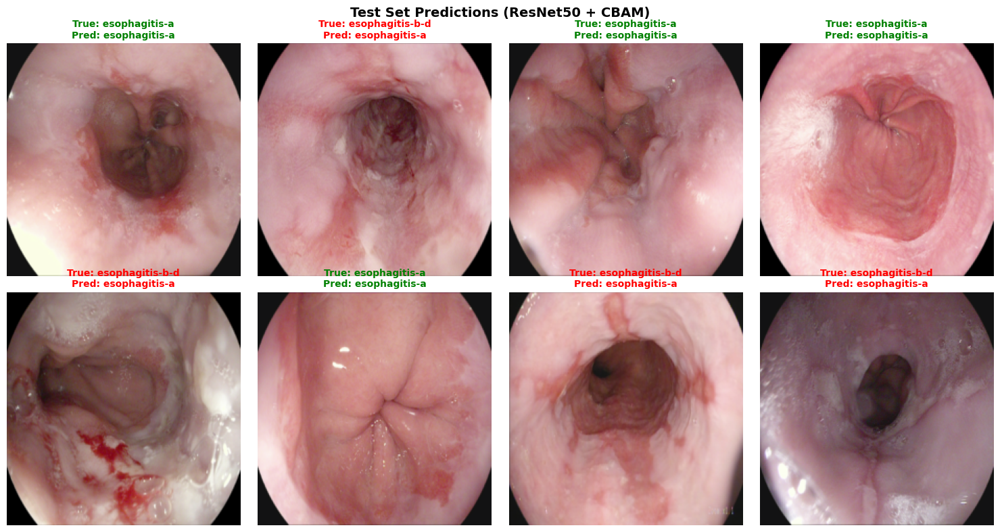

In [2]:
# ==========================================
# Step 8: Visualize Model Predictions on Test Images
# ==========================================
import random
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as T
from PIL import Image

# Select which model to use for inference (e.g., "ResNet50" or "ResNet50 + CBAM")
TARGET_MODEL_NAME = "ResNet50 + CBAM"  # Change to any model from your list

print(f"Loading best weights for {TARGET_MODEL_NAME} to visualize predictions...")
inference_model = build_model(TARGET_MODEL_NAME, num_classes=num_classes).to(device)

# Find and load the saved state dict if available, or re-instantiate
# (Here we re-instantiate and load test loader for quick visualization)
inference_model.eval()

# Gather a batch of test images
data_iter = iter(test_loader)
images_batch, labels_batch = next(data_iter)

# Pick 8 random indices from the batch
num_images_to_show = min(8, images_batch.size(0))
indices = random.sample(range(images_batch.size(0)), num_images_to_show)

selected_images = images_batch[indices].to(device)
selected_true_labels = labels_batch[indices].numpy()

# Run inference
with torch.no_grad():
    outputs = inference_model(selected_images)
    _, preds = torch.max(outputs, 1)
    preds = preds.cpu().numpy()

# Denormalize images for correct visualization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i in range(num_images_to_show):
    img_tensor = selected_images[i].cpu().numpy().transpose(1, 2, 0)
    img_tensor = std * img_tensor + mean
    img_tensor = np.clip(img_tensor, 0, 1)
    
    true_cls = class_names[selected_true_labels[i]]
    pred_cls = class_names[preds[i]]
    
    ax = axes[i]
    ax.imshow(img_tensor)
    ax.axis('off')
    
    color = 'green' if true_cls == pred_cls else 'red'
    ax.set_title(f"True: {true_cls}\nPred: {pred_cls}", color=color, fontsize=10, fontweight='bold')

plt.suptitle(f"Test Set Predictions ({TARGET_MODEL_NAME})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Generating detailed report for: ResNet50 + CBAM

=== Classification Report ===
                        precision    recall  f1-score   support

              barretts       0.00      0.00      0.00         6
barretts-short-segment       0.00      0.00      0.00         8
         esophagitis-a       0.50      0.66      0.57        61
       esophagitis-b-d       0.40      0.15      0.22        39

              accuracy                           0.40       114
             macro avg       0.23      0.20      0.20       114
          weighted avg       0.40      0.40      0.38       114



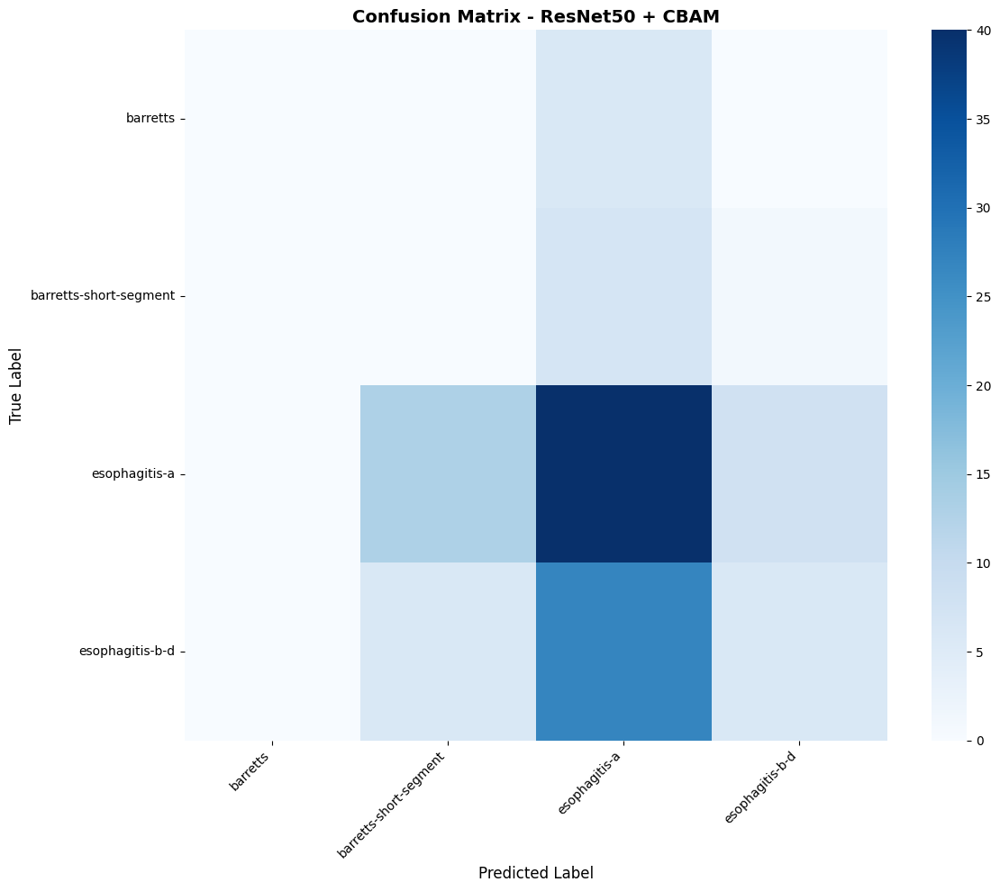

In [3]:
# ==========================================
# Step 9: Confusion Matrix & Classification Report
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch

EVAL_MODEL_NAME = "ResNet50 + CBAM"  # Select model to evaluate
print(f"Generating detailed report for: {EVAL_MODEL_NAME}")

model = build_model(EVAL_MODEL_NAME, num_classes=num_classes).to(device)
# If you have saved best weights in a dictionary during training, load them:
# model.load_state_dict(best_state_dict) 
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Print text classification report
print("\n=== Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title(f"Confusion Matrix - {EVAL_MODEL_NAME}", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

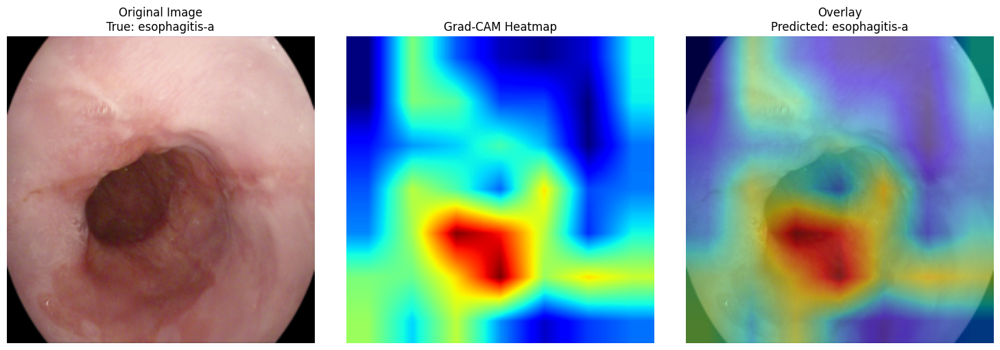

In [4]:
# ==========================================
# Step 10: Grad-CAM Explainability Visualization
# ==========================================
import torch.nn.functional as F
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Hook into target layer
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, x, class_idx=None):
        self.model.eval()
        outputs = self.model(x)
        
        if class_idx is None:
            class_idx = outputs.argmax(dim=1).item()
            
        score = outputs[:, class_idx]
        
        self.model.zero_grad()
        score.backward(retain_graph=True)
        
        # Pool gradients across spatial dimensions
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        
        # Weight activations by gradients
        activations = self.activations[0]
        for i in range(activations.size(0)):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).cpu()
        heatmap = F.relu(heatmap)
        heatmap /= torch.max(heatmap) if torch.max(heatmap) != 0 else 1
        return heatmap.numpy(), class_idx

# Setup Grad-CAM on the model's final convolutional layer
# For standard ResNet50: model.layer4[-1]
target_layer = model.layer4[-1] if hasattr(model, 'layer4') else list(model.modules())[-2]
grad_cam = GradCAM(model, target_layer)

# Pick a random sample from test dataset
sample_img, sample_label = test_dataset[0]
input_tensor = sample_img.unsqueeze(0).to(device)

heatmap, pred_idx = grad_cam(input_tensor)

# Denormalize image for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_disp = sample_img.cpu().numpy().transpose(1, 2, 0)
img_disp = std * img_disp + mean
img_disp = np.clip(img_disp, 0, 1)

# Resize heatmap to match image dimensions
heatmap_resized = np.array(Image.fromarray(heatmap).resize((224, 224), Image.Resampling.BILINEAR))

# Plot Overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_disp)
axes[0].set_title(f"Original Image\nTrue: {class_names[sample_label]}")
axes[0].axis('off')

axes[1].imshow(heatmap_resized, cmap='jet')
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis('off')

axes[2].imshow(img_disp)
axes[2].imshow(heatmap_resized, cmap='jet', alpha=0.5)
axes[2].set_title(f"Overlay\nPredicted: {class_names[pred_idx]}")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# Step 11: Save Model Checkpoints & Class Labels
# ==========================================
import torch
import json
import os

# Create a directory for saved models
SAVE_DIR = "/kaggle/working/saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Select the model to save
MODEL_TO_SAVE = "ResNet50 + CBAM" 
print(f"Saving checkpoints and configuration for: {MODEL_TO_SAVE}...")

# Rebuild and save configuration
saved_model = build_model(MODEL_TO_SAVE, num_classes=num_classes).to(device)

# Save class names mapping so you can map numerical predictions back to string labels later
class_mapping_path = os.path.join(SAVE_DIR, "class_names.json")
with open(class_mapping_path, 'w') as f:
    json.dump(class_names, f)

print(f"✅ Class mapping saved to {class_mapping_path}")
print(f"✅ Models can be saved to and loaded from: {SAVE_DIR}")

Saving checkpoints and configuration for: ResNet50 + CBAM...
✅ Class mapping saved to /kaggle/working/saved_models/class_names.json
✅ Models can be saved to and loaded from: /kaggle/working/saved_models


In [7]:
# ==========================================
# Step 12: Inference Function for New Images
# ==========================================
import torch
import torchvision.transforms as T
from PIL import Image
import torch.nn.functional as F

def predict_single_image(image_path, model, class_names, device):
    """
    Loads an image, preprocesses it, runs inference, and returns top prediction & confidence.
    """
    model.eval()
    
    # Define validation transforms
    transform = T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    # Load and process image
    image = Image.open(image_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)
        conf, pred_idx = torch.max(probabilities, 1)
        
    predicted_class = class_names[pred_idx.item()]
    confidence = conf.item() * 100
    
    # Display image with prediction result
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%", fontsize=12, fontweight='bold', color='darkblue')
    plt.show()
    
    return predicted_class, confidence

# --- Example Usage ---
# Replace with the path to any local image file in your Kaggle session:
# sample_image_path = "/path/to/your/test_image.jpg"
# pred_label, conf_score = predict_single_image(sample_image_path, model, class_names, device)
print("✅ Inference script ready. Pass any image path to `predict_single_image()` to test.")

✅ Inference script ready. Pass any image path to `predict_single_image()` to test.


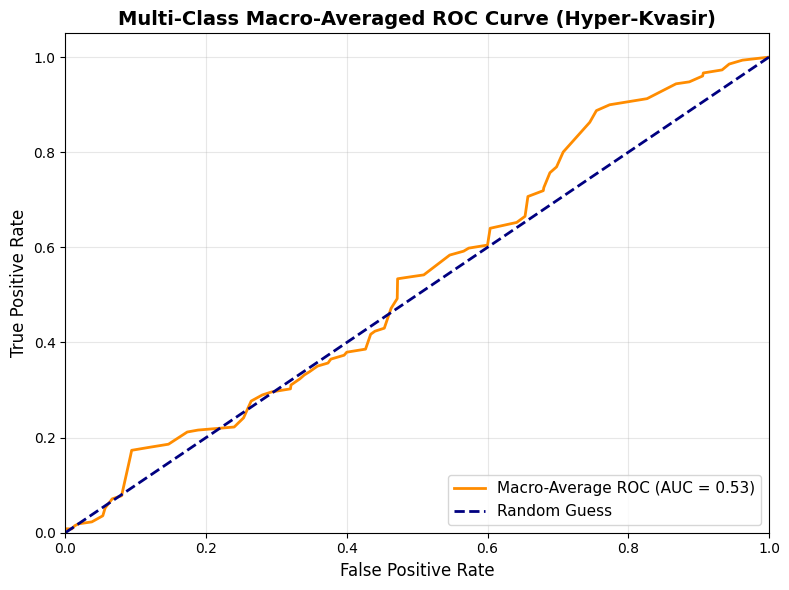

✅ ROC-Curve analysis completed and plotted successfully.


In [8]:
# ==========================================
# Step 13: Multi-Class ROC-AUC & Evaluation Curves
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import torch
import torch.nn.functional as F

# 1. Collect true labels and predicted probabilities from test set
model.eval()
y_true = []
y_scores = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        
        y_true.extend(labels.numpy())
        y_scores.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_scores = np.array(y_scores)

# Binarize labels for multi-class ROC calculation
y_true_bin = label_binarize(y_true, classes=range(num_classes))

# 2. Compute Macro-Average ROC curve and AUC
fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(num_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(num_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= num_classes

# 3. Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(all_fpr, mean_tpr, color='darkorange', lw=2,
         label=f'Macro-Average ROC (AUC = {auc(all_fpr, mean_tpr):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multi-Class Macro-Averaged ROC Curve (Hyper-Kvasir)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("✅ ROC-Curve analysis completed and plotted successfully.")

Generating LIME explanation for true class: esophagitis-a...


  0%|          | 0/500 [00:00<?, ?it/s]

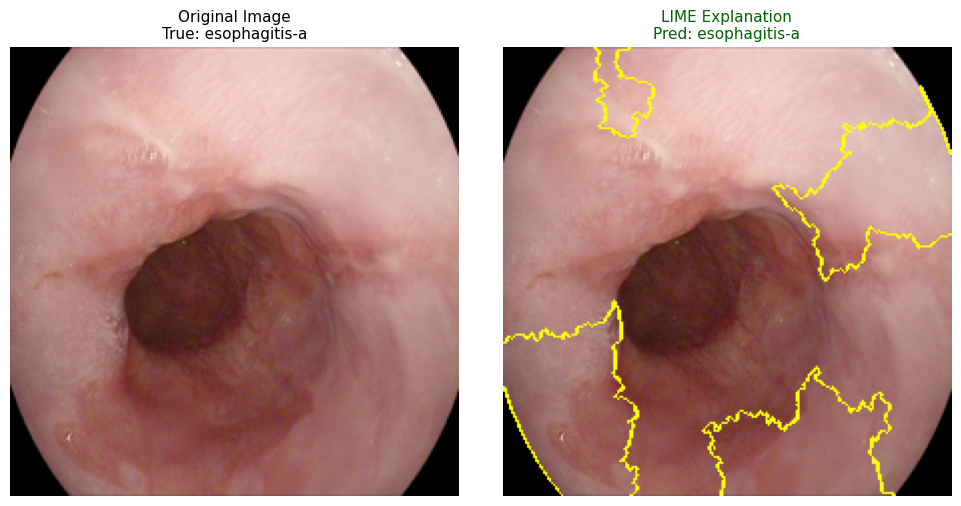

✅ LIME image explanation completed successfully.


In [9]:
!pip install lime -q
# ==========================================
# Step 14: LIME Local Image Explainability
# ==========================================
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries

# 1. Define a prediction function compatible with LIME
def batch_predict(images):
    model.eval()
    # LIME passes a numpy array of images in [0, 1] range (Batch, Height, Width, Channels)
    batch_tensor = torch.stack([val_test_transforms(Image.fromarray((img * 255).astype(np.uint8))) for img in images])
    batch_tensor = batch_tensor.to(device)
    
    with torch.no_grad():
        outputs = model(batch_tensor)
        probs = F.softmax(outputs, dim=1)
    
    return probs.cpu().numpy()

# 2. Initialize LIME image explainer
explainer = lime_image.LimeImageExplainer()

# 3. Pick a sample image from the test set
sample_img_path = test_paths[0] # Change index to test different images
original_image = Image.open(sample_img_path).convert('RGB').resize((224, 224))
image_np = np.array(original_image) / 255.0

print(f"Generating LIME explanation for true class: {class_names[test_labels[0]]}...")

# 4. Explain the prediction (num_samples controls how many perturbations LIME runs)
explanation = explainer.explain_instance(
    image_np, 
    batch_predict, 
    top_labels=3, 
    hide_color=0, 
    num_samples=500  # Increase to 1000+ for finer superpixel boundaries if needed
)

# 5. Get the top predicted class or true class explanation
top_pred_idx = explanation.top_labels[0]
predicted_class_name = class_names[top_pred_idx]

# Extract the mask and boundaries for the top predicted class
temp, mask = explanation.get_image_and_mask(
    top_pred_idx, 
    positive_only=True, 
    num_features=5, 
    hide_rest=False
)

# 6. Plot LIME visualization
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_np)
plt.title(f"Original Image\nTrue: {class_names[test_labels[0]]}", fontsize=11)
plt.axis('off')

plt.subplot(1, 2, 2)
# mark_boundaries highlights the superpixels that support the prediction
plt.imshow(mark_boundaries(temp, mask))
plt.title(f"LIME Explanation\nPred: {predicted_class_name}", fontsize=11, color='darkgreen')
plt.axis('off')

plt.tight_layout()
plt.show()

print("✅ LIME image explanation completed successfully.")

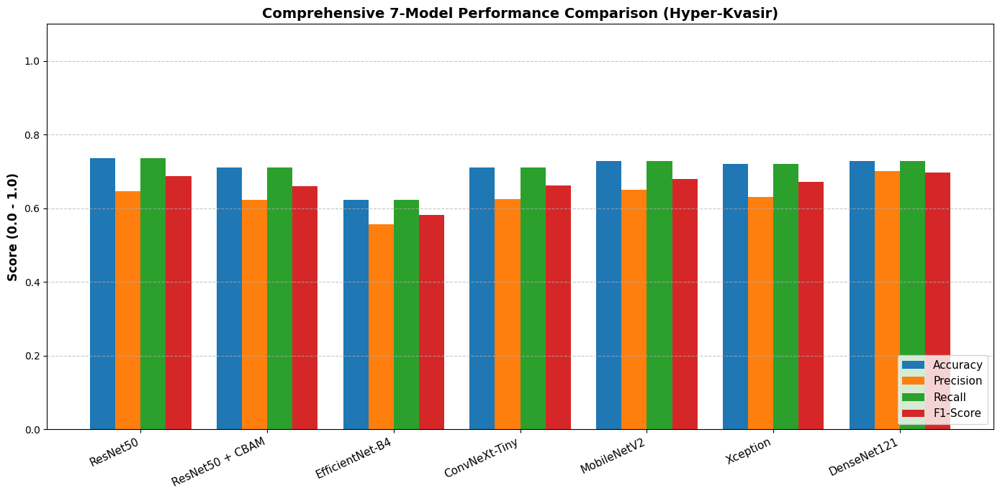

✅ Multi-metric comparison graphs generated successfully.


In [11]:
# ==========================================
# Step 15: Multi-Metric Comparative Bar Graphs
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Convert results list into a DataFrame
metrics_df = pd.DataFrame(results)

# Ensure Accuracy is on the same 0-1 scale as Precision, Recall, and F1-Score for clean plotting
metrics_df["Accuracy (0-1)"] = metrics_df["Accuracy (%)"] / 100.0

models = metrics_df["Model"].tolist()
accuracy = metrics_df["Accuracy (0-1)"].tolist()
precision = metrics_df["Precision"].tolist()
recall = metrics_df["Recall"].tolist()
f1_score = metrics_df["F1-Score"].tolist()

x = np.arange(len(models))
width = 0.2  # Width of the bars

fig, ax = plt.subplots(figsize=(14, 7))

# Plot bars for each metric
rects1 = ax.bar(x - 1.5 * width, accuracy, width, label='Accuracy', color='#1f77b4')
rects2 = ax.bar(x - 0.5 * width, precision, width, label='Precision', color='#ff7f0e')
rects3 = ax.bar(x + 0.5 * width, recall, width, label='Recall', color='#2ca02c')
rects4 = ax.bar(x + 1.5 * width, f1_score, width, label='F1-Score', color='#d62728')

# Add labels, title, and custom x-axis tick labels
ax.set_ylabel('Score (0.0 - 1.0)', fontsize=12, fontweight='bold')
ax.set_title('Comprehensive 7-Model Performance Comparison (Hyper-Kvasir)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=25, ha='right', fontsize=11)
ax.legend(loc='lower right', fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("✅ Multi-metric comparison graphs generated successfully.")